In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from  sklearn.preprocessing import LabelEncoder, StandardScaler
import tensorflow as tf
from tensorflow.keras import layers,models

In [2]:
data=pd.read_csv("hotel_bookings 2.csv")

In [3]:
data.head(10)

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,1/7/2015
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,1/7/2015
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2/7/2015
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2/7/2015
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,3/7/2015
5,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,3/7/2015
6,Resort Hotel,0,0,2015,July,27,1,0,2,2,...,No Deposit,NaN,NaN,0,Transient,107.0,0,0,Check-Out,3/7/2015
7,Resort Hotel,0,9,2015,July,27,1,0,2,2,...,No Deposit,303.0,NaN,0,Transient,103.0,0,1,Check-Out,3/7/2015
8,Resort Hotel,1,85,2015,July,27,1,0,3,2,...,No Deposit,240.0,NaN,0,Transient,82.0,0,1,Canceled,6/5/2015
9,Resort Hotel,1,75,2015,July,27,1,0,3,2,...,No Deposit,15.0,NaN,0,Transient,105.5,0,0,Canceled,22/4/2015


In [4]:
data.isnull()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,False,False,False,False,False,False,False,False,False,False,...,False,True,True,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,True,True,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,True,True,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,True,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,True,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119385,False,False,False,False,False,False,False,False,False,False,...,False,False,True,False,False,False,False,False,False,False
119386,False,False,False,False,False,False,False,False,False,False,...,False,False,True,False,False,False,False,False,False,False
119387,False,False,False,False,False,False,False,False,False,False,...,False,False,True,False,False,False,False,False,False,False
119388,False,False,False,False,False,False,False,False,False,False,...,False,False,True,False,False,False,False,False,False,False


In [5]:
data.duplicated()

0         False
1         False
2         False
3         False
4         False
          ...  
119385    False
119386    False
119387    False
119388    False
119389    False
Length: 119390, dtype: bool

In [6]:
data=data.dropna()

In [7]:
data=data.drop_duplicates()

In [8]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 189 entries, 2392 to 116451
Data columns (total 32 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   hotel                           189 non-null    object 
 1   is_canceled                     189 non-null    int64  
 2   lead_time                       189 non-null    int64  
 3   arrival_date_year               189 non-null    int64  
 4   arrival_date_month              189 non-null    object 
 5   arrival_date_week_number        189 non-null    int64  
 6   arrival_date_day_of_month       189 non-null    int64  
 7   stays_in_weekend_nights         189 non-null    int64  
 8   stays_in_week_nights            189 non-null    int64  
 9   adults                          189 non-null    int64  
 10  children                        189 non-null    float64
 11  babies                          189 non-null    int64  
 12  meal                            189

In [9]:
Le=LabelEncoder()
for i in data.select_dtypes(include=["object"]).columns:
    le=LabelEncoder()
    data[i]=le.fit_transform(data[i].astype(str))
data.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
2392,1,0,6,2015,10,42,11,2,0,2,...,0,240.0,113.0,0,2,82.0,1,1,1,17
2697,1,0,24,2015,10,44,26,7,15,1,...,0,185.0,281.0,0,3,52.2,0,0,1,34
2867,1,0,24,2015,9,45,3,0,3,2,...,0,334.0,281.0,0,3,48.0,0,0,1,68
2877,1,0,24,2015,9,45,3,2,10,1,...,0,328.0,281.0,0,3,40.0,0,0,1,23
2878,1,0,24,2015,9,45,3,3,10,2,...,0,326.0,281.0,0,3,48.0,0,0,1,29


In [10]:
features=data.drop("reservation_status",axis=1)
X=features
y=data["reservation_status"]

In [11]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)
print(X_train.shape)
print(y_train.shape)

(151, 31)
(151,)


In [12]:
def create_ann_model(input_dim):
    try:
        model = models.Sequential([
            layers.Input(shape=(input_dim,)),
            layers.Dense(32, activation="relu"),
            layers.Dense(16, activation="relu"),
            layers.Dense(1, activation="sigmoid")  # binary classification
        ])
        model.compile(
            optimizer="adam",
            loss="binary_crossentropy",
            metrics=["accuracy"]
        )
        return model
    except Exception as e:
        raise Exception(f"Model creation error: {e}")
try:
    model = create_ann_model(X_train.shape[1])
    model.summary()
except Exception as e:
    raise Exception(f"Model initialization error: {e}")
try:
    history = model.fit(
        X_train, y_train,
        epochs=20,
        batch_size=64,
        validation_split=0.2,
        verbose=1
    )
except Exception as e:
    raise Exception(f"Training error: {e}")

print("Model training complete.")
try:
    loss, accuracy = model.evaluate(X_test, y_test, verbose=1)
    print("Test Loss:", loss)
    print("Test Accuracy:", accuracy)
except Exception as e:
    raise Exception(f"Evaluation error: {e}")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 32)                  │           1,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │              17 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,569 (6.13 KB)

 Trainable params: 1,569 (6.13 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 3s 519ms/step - accuracy: 0.9083 - loss: 5.9558 - val_accuracy: 0.9677 - val_loss: -2.0797
Epoch 2/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 142ms/step - accuracy: 0.9083 - loss: 3.5667 - val_accuracy: 0.9677 - val_loss: -0.7893
Epoch 3/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 158ms/step - accuracy: 0.9083 - loss: 1.4664 - val_accuracy: 0.0968 - val_loss: 7.2589
Epoch 4/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 181ms/step - accuracy: 0.3667 - loss: 3.5318 - val_accuracy: 0.8710 - val_loss: 0.1394
Epoch 5/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step - accuracy: 0.9000 - loss: 0.7231 - val_accuracy: 0.9677 - val_loss: -0.5228
Epoch 6/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step - accuracy: 0.9083 - loss: 1.4511 - val_accuracy: 0.9677 - val_loss: -0.8208
Epoch 7/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 156ms/step - accuracy: 0.9083 - loss: 2.0631 - val_accuracy: 0.9677 - val_loss: -1.0004
Epoch 8/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 159ms/step - accuracy: 0.9083 - loss: 2.2904 - val_accuracy: 0.9677 - val_

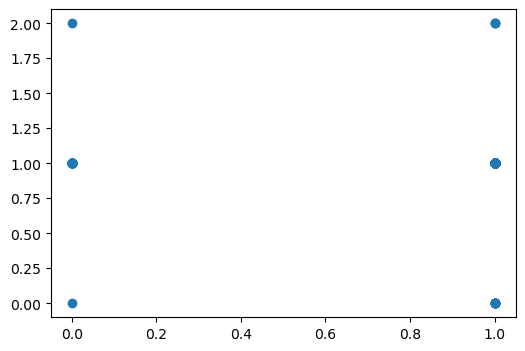

In [14]:
plt.figure(figsize=(6,4))
plt.scatter(X.iloc[:,0],y)
plt.show()